# Heat Conduction with Variable Conductivity and Moving Boundary Data

The temperature $u$ in a body with thermal conductivity $k$ and heat sources $s$ obeys the heat equation
(for unit heat capacity)

$$
\frac{\partial u}{\partial t} = \nabla \cdot \bigl( k\, \nabla u \bigr) + s .
$$

The notebook [Heat Diffusion in a Rod](heat-equation-rod.ipynb) treats the simplest case: constant
conductivity, no source, boundary conditions that do not change in time. Here we go further:

1. a plate whose conductivity varies in space, with the operator $\nabla \cdot (k \nabla u)$ from
   `grid.diffusion_operator(k)`,
2. the ground under a surface whose temperature follows the seasons: a **time-dependent boundary value**
   on a half space,
3. a disk heated by a **moving source**, with a balance of the heat that enters, leaves and stays,
4. implicit time stepping written by hand with a **reusable factorization**, `Operator.factorize`.

Each result is compared with an exact solution or checked with a conservation law.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from numgrids import *

## 1. A Plate with Graded Conductivity

In a *functionally graded material* the composition, and with it the conductivity, changes gradually
across the body. We take a square plate with $k(x) = e^{2ax}$. The left edge is heated,
$u(0, y) = \sin \pi y$, and the other edges are kept at temperature 0. The steady temperature solves

$$
\nabla \cdot \bigl( k\, \nabla u \bigr) = 0 ,
$$

and for this conductivity the solution is known:

$$
u(x, y) = \sin(\pi y)\; e^{-ax}\, \frac{\sinh\bigl(\sigma (1 - x)\bigr)}{\sinh \sigma}, \qquad \sigma = \sqrt{a^2 + \pi^2} .
$$

`grid.diffusion_operator(k)` builds the operator $u \mapsto \nabla \cdot (k \nabla u)$. The coefficient is
a number, an array on the grid or a function of the coordinates. `solve` takes the boundary values as
usual. The heat current density is $\mathbf{q} = -k \nabla u$, and `face.flux` integrates its normal
component over a boundary face. In the steady state, all the heat that enters through the hot edge must
leave through the three others.

In [2]:
plate = Grid(x=chebyshev(24, 0, 1), y=chebyshev(24, 0, 1))
X, Y = plate.meshed_coords
plate_bcs = {"x_low": lambda c: np.sin(np.pi * c[1]), "x_high": 0, "y_low": 0, "y_high": 0}


def exact_plate(a):
    sigma = np.sqrt(a**2 + np.pi**2)
    return np.sin(np.pi * Y) * np.exp(-a * X) * np.sinh(sigma * (1 - X)) / np.sinh(sigma)


def outflow(u, k, face):
    q = [-k * du for du in plate.gradient(u)]          # heat current density
    return plate.faces[face].flux(*q)                  # heat leaving through the face


plates = {}
print("   a     max. error    mean temperature    heat in      heat out")
for a in (-2.0, 0.0, 2.0):
    k = np.exp(2 * a * X)
    u = plate.diffusion_operator(k).solve(0, bcs=plate_bcs)
    plates[a] = u
    heat_in = -outflow(u, k, "x_low")
    heat_out = sum(outflow(u, k, face) for face in ("x_high", "y_low", "y_high"))
    print(f"{a:5.1f}    {plate.norm(u - exact_plate(a), 'max'):.1e}       {plate.mean(u):.6f}"
          f"        {heat_in:10.6f}   {heat_out:10.6f}")

   a     max. error    mean temperature    heat in      heat out
 -2.0    7.0e-13       0.283787          1.100418     1.100418
  0.0    5.1e-13       0.185854          2.007484     2.007484
  2.0    4.1e-12       0.109926          3.646897     3.646897


The numerical solutions agree with the exact ones to 11 digits or better, and the heat balance closes:
what enters through the hot edge leaves through the three cold ones.

The grading matters. If the conductivity decreases away from the hot edge ($a = -2$), the poorly
conducting far side insulates the plate. The plate stays warm, and only about half as much heat flows as
in the homogeneous plate ($a = 0$). If the conductivity increases towards the cold edges ($a = 2$), the
heat is carried away easily: the plate stays cool although almost twice as much heat flows through it.
The plot shows the two graded plates with isotherms at intervals of 0.1.

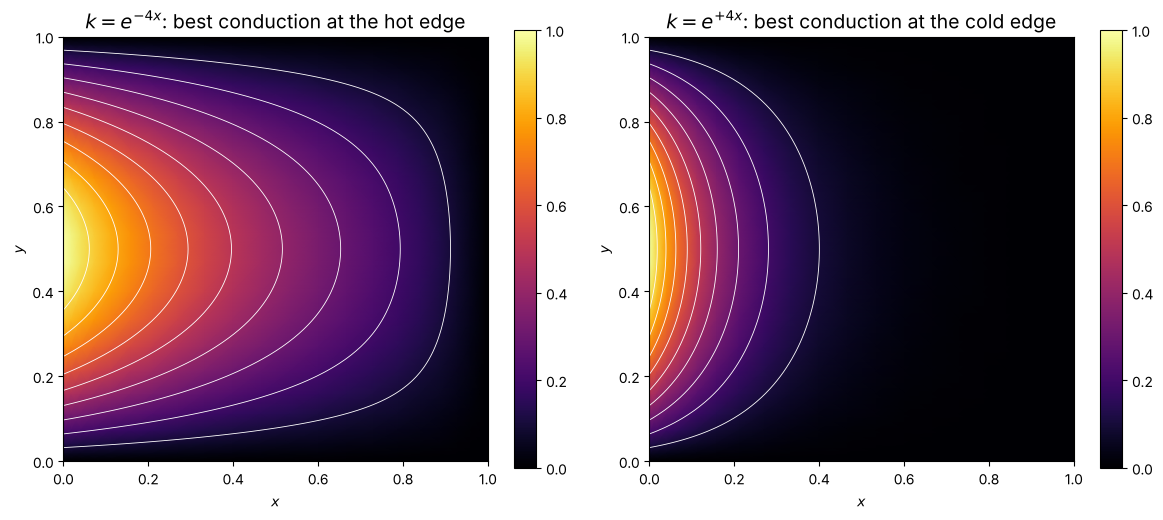

In [3]:
# a fine mesh for smooth isotherms (spectral interpolation)
fine = np.linspace(0, 1, 101)
XF, YF = np.meshgrid(fine, fine, indexing="ij")
points = np.column_stack([XF.ravel(), YF.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, a in zip(axes, (-2.0, 2.0)):
    plate.plot(plates[a], ax=ax, cmap="inferno", vmin=0, vmax=1)
    u_fine = plate.interpolate(plates[a], points, method="spectral").reshape(XF.shape)
    ax.contour(XF, YF, u_fine, levels=np.arange(0.1, 1.0, 0.1), colors="white", linewidths=0.6)
    ax.set_aspect("equal")
    side = "hot" if a < 0 else "cold"
    ax.set_title(f"$k = e^{{{2 * a:+.0f}x}}$: best conduction at the {side} edge", fontsize=14)
fig.tight_layout()
plt.show()

## 2. The Seasons Underground

The temperature of the ground surface follows the seasons, $u(0, t) = \bar u + A \sin \omega t$. How deep
does the annual cycle reach? The ground is a half space, $0 \le z < \infty$, and the heat equation
$\partial_t u = \kappa\, \partial_z^2 u$ has the periodic solution

$$
u(z, t) = \bar u + A\, e^{-z/d} \sin\!\left(\omega t - \frac{z}{d}\right), \qquad d = \sqrt{\frac{2\kappa}{\omega}} :
$$

a *thermal wave* that travels downwards and is damped by the factor $e^{-2\pi} \approx 0.002$ over one
wavelength $2\pi d$.

Two features of *numgrids* fit this problem. The axis `semi_infinite` discretizes the half space itself,
so there is no artificial lower boundary. And `TimeDependent` wraps a function of time as a boundary
value for `evolve`. We measure depth in metres and time in years. A typical soil has the diffusivity
$\kappa \approx 0.5 \cdot 10^{-6}\ \mathrm{m^2/s} \approx 16\ \mathrm{m^2/year}$.

In [4]:
kappa = 16.0                          # thermal diffusivity of the soil in m^2 / year
omega = 2 * np.pi                     # one cycle per year
d = np.sqrt(2 * kappa / omega)        # penetration depth in m
u_mean, amplitude = 10.0, 10.0        # degrees Celsius

ground = Grid(z=semi_infinite(48, scale=15.0))
z = ground.coords


def thermal_wave(t, z=z):
    return u_mean + amplitude * np.exp(-z / d) * np.sin(omega * t - z / d)


surface = TimeDependent(lambda t: u_mean + amplitude * np.sin(omega * t))
years = np.linspace(0, 2, 241)

seasons = evolve(ground, kappa * ground.diff_operator(2), thermal_wave(0.0), t_span=(0, 2),
                 t_eval=years, bcs={"z_low": surface}, method="BDF", rtol=1e-9, atol=1e-10)

exact = np.array([thermal_wave(t) for t in years])
print(f"penetration depth d = {d:.3f} m")
print(f"deepest grid point:   {z[-1]:.0f} m")
print(f"max. error over two years: {np.max(np.abs(seasons.u - exact)):.1e} degrees")

penetration depth d = 2.257 m
deepest grid point:   54855 m
max. error over two years: 1.2e-07 degrees


The solution of `evolve` follows the exact thermal wave to $10^{-7}$ degrees over two years. We started
from the exact wave at $t = 0$, so there is no transient. The temperature far below the surface stays at
the mean value $\bar u$: a function on a `semi_infinite` axis may tend to a constant at infinity.

At the depth $\pi d \approx 7.1$ m the wave arrives half a year late. The ground there is coldest in
midsummer and warmest in midwinter, with an amplitude of only $A\,e^{-\pi} \approx 0.43$ degrees.
`grid.interpolate` evaluates the numerical solution at this depth, between the grid points:

In [5]:
depth = np.pi * d
print(f"depth {depth:.2f} m           numerical     exact")
for label, t in [("midsummer (t = 1.25)", 1.25), ("midwinter (t = 1.75)", 1.75)]:
    u_t = seasons.u[np.argmin(np.abs(years - t))]
    value = ground.interpolate(u_t, depth, method="spectral")
    print(f"{label}    {float(value):.6f}    {thermal_wave(t, depth):.6f}")

depth 7.09 m           numerical     exact
midsummer (t = 1.25)    9.567861    9.567861
midwinter (t = 1.75)    10.432139    10.432139


The left panel shows the temperature profiles in the middle of the four seasons (gray: the months in
between), with the values at the grid points as markers. All profiles stay inside the envelope
$\bar u \pm A\,e^{-z/d}$. The right panel shows the whole solution: the crests of the thermal wave travel
downwards with the velocity $\omega d \approx 14$ m per year and fade out within about ten metres.

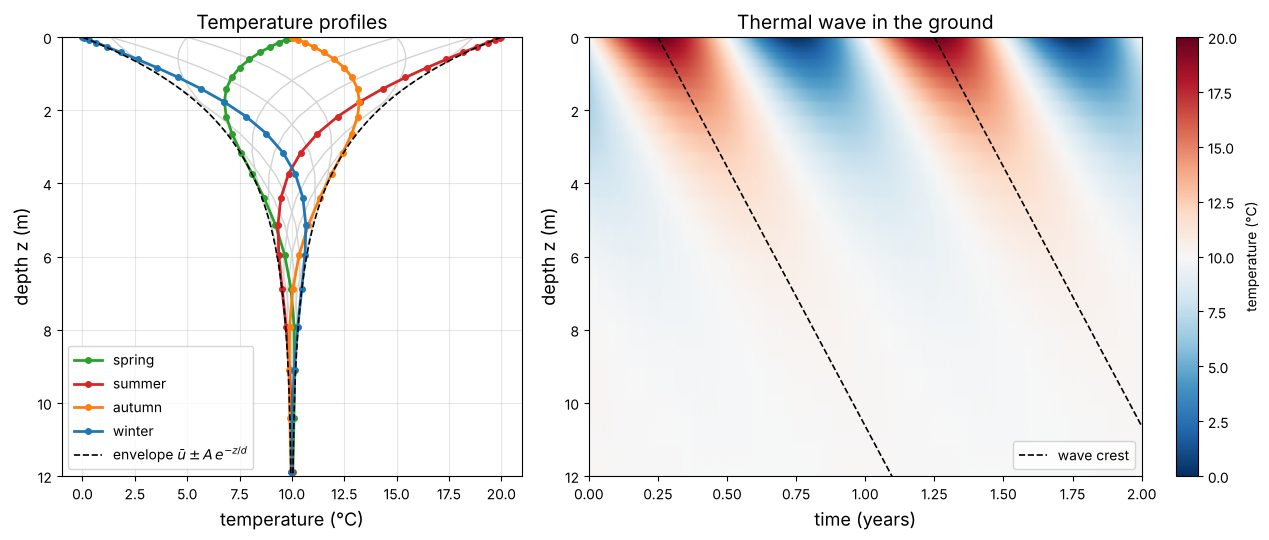

In [6]:
z_fine = np.linspace(0, 12, 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), width_ratios=[1, 1.5])

for j in range(120, 240, 10):                           # once a month in the second year
    ax1.plot(seasons.u[j], z, color="lightgray", linewidth=1)
for label, j, color in [("spring", 120, "tab:green"), ("summer", 150, "tab:red"),
                        ("autumn", 180, "tab:orange"), ("winter", 210, "tab:blue")]:
    ax1.plot(seasons.u[j], z, "o-", color=color, linewidth=2, markersize=4, label=label)
for sign in (-1, 1):
    ax1.plot(u_mean + sign * amplitude * np.exp(-z_fine / d), z_fine, "k--", linewidth=1.2,
             label=r"envelope $\bar u \pm A\,e^{-z/d}$" if sign == 1 else None)
ax1.set_ylim(12, 0)
ax1.set_xlabel("temperature (°C)", fontsize=13)
ax1.set_ylabel("depth z (m)", fontsize=13)
ax1.set_title("Temperature profiles", fontsize=14)
ax1.legend(loc="lower left", fontsize=10)
ax1.grid(True, alpha=0.3)

im = ax2.pcolormesh(years, z, seasons.u.T, cmap="RdBu_r", shading="gouraud", vmin=0, vmax=20)
for year in (0, 1):
    crest = d * (omega * (years - year) - np.pi / 2)    # depth of the wave crest of that year
    ax2.plot(years[crest >= 0], crest[crest >= 0], "k--", linewidth=1.2,
             label="wave crest" if year == 0 else None)
ax2.set_ylim(12, 0)
ax2.set_xlabel("time (years)", fontsize=13)
ax2.set_ylabel("depth z (m)", fontsize=13)
ax2.set_title("Thermal wave in the ground", fontsize=14)
ax2.legend(loc="lower right", fontsize=10)
fig.colorbar(im, ax=ax2, label="temperature (°C)")

fig.tight_layout()
plt.show()

## 3. A Disk with a Moving Heat Source

Now a problem in two dimensions with a source term. A disk of radius 1 conducts heat better towards its
rim, $k(r) = 1 + 3r^2$. A heater travels around the disk on a circle of radius $0.4$, once per unit of
time, and is switched on smoothly. The rim loses heat to the surroundings (temperature 0) according to
Newton's law of cooling,

$$
-k\, \frac{\partial u}{\partial n} = h\, u \qquad \text{at } r = 1 ,
$$

a Robin condition, `Robin(h, k, 0)` with the conductivity $k(1) = 4$ at the rim. The source is passed to `evolve` as a function of time, `source=`.
With an operator as right-hand side the problem stays linear, and the implicit method uses the exact
Jacobian.

A `PolarGrid` with a `radial` axis covers the full disk. Its only boundary is the rim.

In [7]:
disk = PolarGrid(radial(18, 1.0), periodic(36))
R, Phi = disk.meshed_coords
Xc, Yc = disk.cartesian_coords                        # Cartesian coordinates of the grid points

k = 1 + 3 * R**2
L = disk.diffusion_operator(k)                        # u -> div(k grad u)

h = 2.0
rim = disk.faces["r_high"]
k_rim = 4.0                                           # conductivity at the rim, k(1)
bcs = {"r_high": Robin(h, k_rim, 0)}                  # h u + k du/dn = 0


def heater_position(t):
    return 0.4 * np.cos(2 * np.pi * t), 0.4 * np.sin(2 * np.pi * t)


def source(t):
    x0, y0 = heater_position(t)
    switch_on = 1 - np.exp(-(t / 0.25)**2)
    return switch_on * 10 * np.exp(-((Xc - x0)**2 + (Yc - y0)**2) / (2 * 0.2**2))


times = np.linspace(0, 3, 301)
heated = evolve(disk, L, np.zeros(disk.shape), t_span=(0, 3), t_eval=times, bcs=bcs,
                method="BDF", source=source, rtol=1e-7, atol=1e-9)

print(heated.message)
print("solution array:", heated.u.shape, "(time, r, phi)")
print(f"mean temperature at the end: {disk.mean(heated.final):.6f}")

The solver successfully reached the end of the integration interval.
solution array: (301, 18, 36) (time, r, phi)
mean temperature at the end: 0.258699


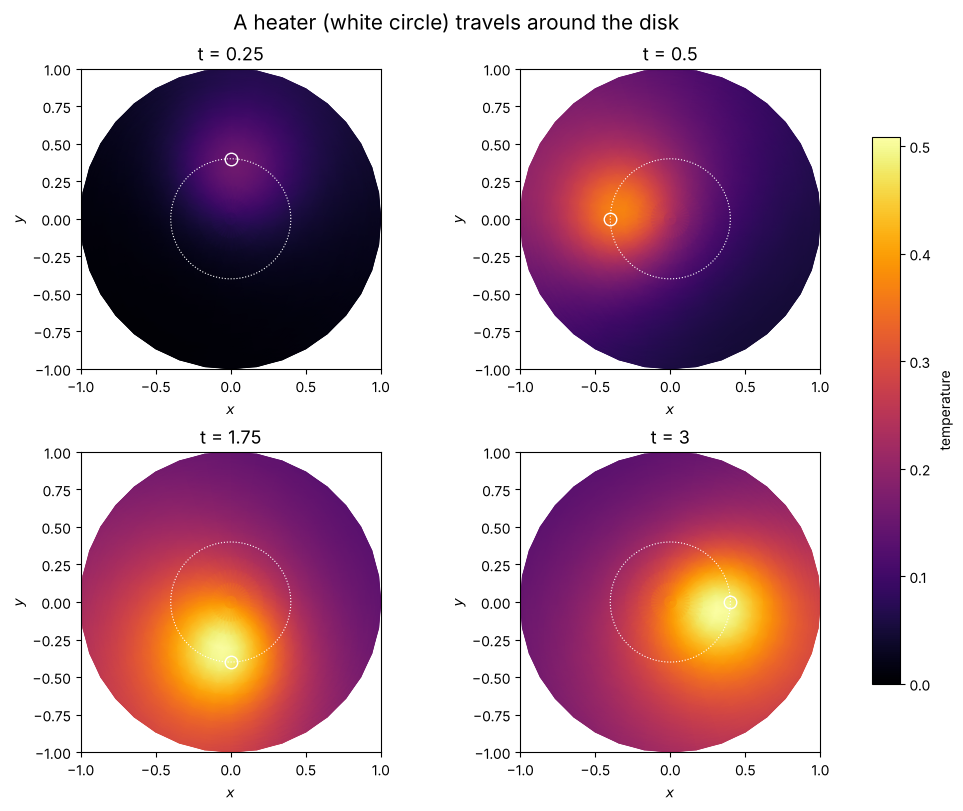

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
u_max = heated.u.max()
circle = np.linspace(0, 2 * np.pi, 200)
for ax, t in zip(axes.flat, (0.25, 0.5, 1.75, 3.0)):
    u_t = heated.u[np.argmin(np.abs(times - t))]
    disk.plot(u_t, ax=ax, cmap="inferno", vmin=0, vmax=u_max, colorbar=False)
    ax.plot(0.4 * np.cos(circle), 0.4 * np.sin(circle), color="white", linestyle=":", linewidth=0.8)
    ax.plot(*heater_position(t), "o", markerfacecolor="none", markeredgecolor="white", markersize=9)
    ax.set_title(f"t = {t:g}", fontsize=13)
fig.colorbar(axes[0, 0].collections[0], ax=axes, label="temperature", shrink=0.8)
fig.suptitle("A heater (white circle) travels around the disk", fontsize=15)
plt.show()

### Heat balance

The total heat in the disk is $Q = \int u\, dA$. It can only change by the power of the heater and by
the heat current through the rim:

$$
\frac{dQ}{dt} = \int s\, dA - \oint \mathbf{q} \cdot \mathbf{n}\, dl, \qquad \mathbf{q} = -k \nabla u .
$$

`disk.integrate` computes the area integrals and `rim.flux` the heat current through the rim. We
integrate both powers over time with Simpson's rule and compare with the heat that is stored in the disk
at the end.

In [9]:
stored = np.array([disk.integrate(u) for u in heated.u])
power_in = np.array([disk.integrate(source(t)) for t in times])
power_out = np.array([rim.flux(*[-k * du for du in disk.gradient(u)]) for u in heated.u])

supplied = simpson(power_in, x=times)
lost = simpson(power_out, x=times)
print(f"heat supplied by the heater:  {supplied:.8f}")
print(f"heat lost through the rim:    {lost:.8f}")
print(f"heat stored in the disk:      {stored[-1]:.8f}")
print(f"supplied - lost - stored:     {supplied - lost - stored[-1]:.1e}")
print(f"Newton's law at the rim, max |q.n - h u|: "
      f"{np.max(np.abs(-k_rim * rim.normal_derivative(heated.final) - h * rim.restrict(heated.final))):.1e}")

heat supplied by the heater:  6.96748154
heat lost through the rim:    6.15475557
heat stored in the disk:      0.81272602
supplied - lost - stored:     -5.3e-08
Newton's law at the rim, max |q.n - h u|: 7.1e-14


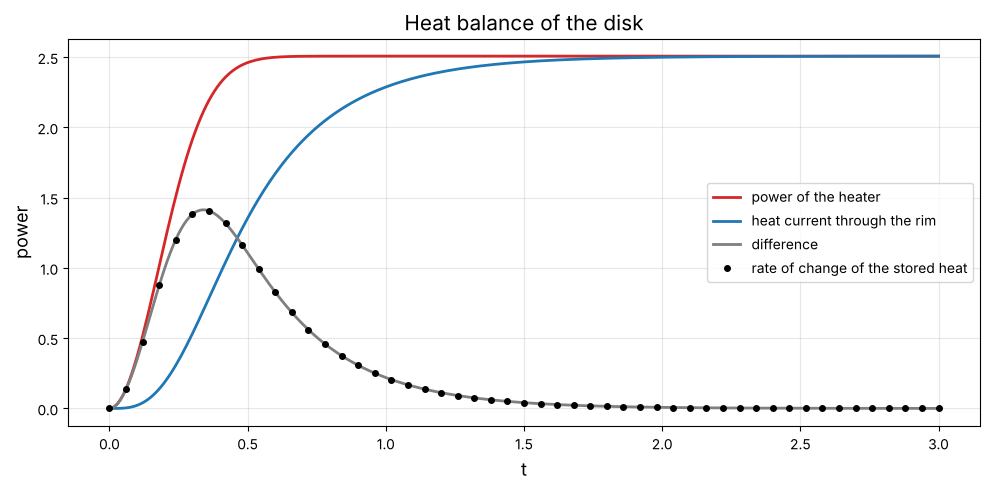

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, power_in, linewidth=2, color="tab:red", label="power of the heater")
ax.plot(times, power_out, linewidth=2, color="tab:blue", label="heat current through the rim")
ax.plot(times, power_in - power_out, linewidth=2, color="tab:gray", label="difference")
ax.plot(times[::6], np.gradient(stored, times)[::6], "o", color="k", markersize=4,
        label="rate of change of the stored heat")
ax.set_xlabel("t", fontsize=13)
ax.set_ylabel("power", fontsize=13)
ax.set_title("Heat balance of the disk", fontsize=15)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

The balance closes to better than $10^{-7}$, which is the accuracy of the time integration and of the
spatial resolution. Newton's law of cooling holds to round-off, because `evolve` computes the values on
the rim from the interior values such that the boundary condition is satisfied at every instant.

After the heater is switched on, it supplies more heat than the rim can release, and the disk warms up.
The rate of change of the stored heat (dots, a finite difference of $Q$ in time) is the difference of
the two powers. From $t \approx 2$ on, the temperature pattern just rotates with the heater, and the rim
releases what the heater supplies. The mean temperature of the disk, `disk.mean(u)`, no longer changes.

## 4. Time Stepping by Hand with a Reusable Factorization

`evolve` chooses its time steps adaptively. To control the time stepping ourselves, we have to solve a
linear system in every step of an implicit scheme. For the implicit Euler method,

$$
\frac{u^{n+1} - u^n}{\Delta t} = L u^{n+1} + s^{n+1}
\qquad \Longleftrightarrow \qquad (1 - \Delta t\, L)\, u^{n+1} = u^n + \Delta t\, s^{n+1} ,
$$

the operator on the left is the same in every step. `Operator.factorize(bcs)` returns a solver that
factorizes it once, including the boundary conditions, and then solves for any number of right-hand
sides. Its attribute `method` tells how the system is solved.

In [11]:
dt = 0.01
step = (1 - dt * L).factorize(bcs=bcs)
print(step)

plate_solver = plate.diffusion_operator(lambda x, y: np.exp(4 * x)).factorize(bcs=plate_bcs)
tilted_solver = (1 - dt * disk.diffusion_operator(2 + Xc)).factorize(bcs=bcs)
print("\ndisk, conductivity depends on r:  ", step.method)
print("disk, conductivity depends on x:  ", tilted_solver.method)
print("plate of section 1:               ", plate_solver.method)

LinearSolver(grid=PolarGrid(18, 36), method='fourier')

disk, conductivity depends on r:   fourier
disk, conductivity depends on x:   dense
plate of section 1:                dense


The disk problem does not depend on the angle $\varphi$: neither the conductivity $k(r)$ nor the boundary
condition does (the source may, it only enters the right-hand side). The solver therefore transforms to
Fourier modes in $\varphi$ and solves one small system with 18 unknowns for each of the 36 modes, instead
of one system with 648 unknowns. If the conductivity depends on the angle, as for $k = 2 + x$, the modes
are coupled, and the solver uses a dense LU factorization, as for the plate.

Here are the implicit Euler method and, for comparison, the Crank-Nicolson scheme, which averages $Lu$
over the old and the new time level and evaluates the source at the midpoint of the step. It is of second
order and needs one factorization as well. We compare both with the solution of `evolve` at $t = 3$.

In [12]:
def implicit_euler(dt, t_end=3.0):
    step = (1 - dt * L).factorize(bcs=bcs)             # factorized once ...
    u = np.zeros(disk.shape)
    for n in range(1, round(t_end / dt) + 1):
        u = step(u + dt * source(n * dt))              # ... and used in every step
    return u


def crank_nicolson(dt, t_end=3.0):
    step = (1 - 0.5 * dt * L).factorize(bcs=bcs)
    explicit = 1 + 0.5 * dt * L
    u = np.zeros(disk.shape)
    for n in range(round(t_end / dt)):
        u = step(explicit(u) + dt * source((n + 0.5) * dt))
    return u


print("   dt      implicit Euler    Crank-Nicolson")
for dt in (0.02, 0.01, 0.005):
    errors = [disk.norm(scheme(dt) - heated.final, "max") for scheme in (implicit_euler, crank_nicolson)]
    print(f"{dt:6.3f}      {errors[0]:.2e}         {errors[1]:.2e}")

   dt      implicit Euler    Crank-Nicolson


 0.020      4.47e-03         8.57e-04


 0.010      2.27e-03         2.12e-04


 0.005      1.15e-03         5.29e-05


Halving the time step halves the error of the implicit Euler method and quarters that of the
Crank-Nicolson scheme, as expected for methods of first and second order.

How much does the reuse of the factorization save? Timings depend on the machine, so we only look at
ratios. First we repeat the 300 implicit Euler steps with `solve`, which factorizes the same matrix again
in every step. Then we compare the cost of one factorization for the three solver methods, on a finer
disk with $32 \times 64$ points.

In [13]:
dt, n_steps = 0.01, 300

start = time.perf_counter()
u = implicit_euler(dt)
t_reuse = time.perf_counter() - start

A = 1 - dt * L
u = np.zeros(disk.shape)
start = time.perf_counter()
for n in range(1, n_steps + 1):
    u = A.solve(u + dt * source(n * dt), bcs=bcs)      # factorizes again in every step
t_solve = time.perf_counter() - start

print(f"300 steps, solving from scratch in every step, take {t_solve / t_reuse:.0f} times as long")
print("as 300 steps with one factorization.")

fine_disk = PolarGrid(radial(32, 1.0), periodic(64))
A_fine = 1 - dt * fine_disk.diffusion_operator(lambda r, phi: 1 + 3 * r**2)
timings = {}
for method in ("fourier", "dense", "sparse"):
    timings[method] = np.inf
    for _ in range(2):                                 # best of two runs
        start = time.perf_counter()
        A_fine.factorize(bcs=bcs, method=method)
        timings[method] = min(timings[method], time.perf_counter() - start)

print(f"\n{fine_disk.size} unknowns: cost of one factorization relative to Fourier decoupling")
for method in ("dense", "sparse"):
    print(f"   {method:7s} {timings[method] / timings['fourier']:5.1f}")

300 steps, solving from scratch in every step, take 13 times as long
as 300 steps with one factorization.



2048 unknowns: cost of one factorization relative to Fourier decoupling
   dense     2.7
   sparse   21.2


The factorization is the expensive part of a solve, so the time stepping is many times faster when it
is done only once. And on the disk, Fourier decoupling is the cheapest way to factorize: dense LU is
more expensive, and sparse LU far more, because the matrices of spectral methods are dense along
each axis and a sparse factorization fills in. The differences grow with the size of the problem.

## Summary

* `grid.diffusion_operator(k)` is the operator $\nabla \cdot (k \nabla u)$ for a conductivity that
  varies in space, on Cartesian and curvilinear grids. It is used like any other operator: with `solve`
  for steady states and with `evolve` for the time-dependent problem.
* `TimeDependent(lambda t: ...)` prescribes boundary values that change in time. Together with
  `semi_infinite` it describes a genuinely semi-infinite solid.
* `evolve(..., source=s)` adds a source term, constant or as a function of time, and keeps the problem
  linear.
* `face.flux`, `grid.integrate` and `grid.mean` give the heat currents, the stored heat and mean
  temperatures for heat balances.
* `Operator.factorize(bcs)` factorizes a linear problem once for many right-hand sides, as needed for
  implicit time stepping. On a disk whose properties do not depend on the angle, the solver decouples the
  Fourier modes, which is much faster than a factorization of the full system.